# Bayesian Portfolio Optimization for Studio Film Strategy
## Exploratory Data Analysis
**STAT 425 · Rice University · Fall 2026**

In [1]:
suppressPackageStartupMessages({
  library(reticulate)
  library(tidyverse)
  library(ggthemes)
})

use_python('/Users/theoauyeung/.venvs/driveline/bin/python', required = TRUE)

options(repr.plot.width = 14, repr.plot.height = 6)

BASE_THEME <- theme_fivethirtyeight() +
  theme(
    axis.title        = element_text(),
    axis.text         = element_text(size = 10),
    panel.background  = element_rect(fill = 'white', color = NA),
    plot.background   = element_rect(fill = 'white', color = NA),
    legend.background = element_rect(fill = 'white', color = NA),
    strip.text        = element_text(size = 12, face = 'bold'),
    plot.title        = element_text(size = 16, face = 'bold')
  )
theme_set(BASE_THEME)

df <- read_csv('../../data/cleaned/movies_clean.csv', show_col_types = FALSE)
cat('Shape:', nrow(df), 'x', ncol(df), '\n')
head(df)

Warning message:
“package ‘reticulate’ was built under R version 4.4.3”


Warning message:
“package ‘dplyr’ was built under R version 4.4.3”


Shape: 3762 x 21 


id,imdb_id,title,year,decade,month,season,budget_adj,revenue_adj,roi,⋯,genre_primary,genres_list,ip_type,studio_label,studio_group,runtime,vote_average,vote_count,original_language,popularity
<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>
862,tt0114709,Toy Story,1995,1990,10,Awards,48900000,608893074,11.4518011,⋯,Animation,"['Animation', 'Comedy', 'Family']",Franchise,Disney - Other,Disney,81,7.7,5415,en,21.946943
8844,tt0113497,Jumanji,1995,1990,12,Awards,105950000,428359516,3.0430346,⋯,Adventure,"['Adventure', 'Fantasy', 'Family']",Adaptation,TriStar Pictures,Sony,104,6.9,2413,en,17.015539
949,tt0113277,Heat,1995,1990,12,Awards,97800000,305522013,2.1239470,⋯,Action,"['Action', 'Crime', 'Drama', 'Thriller']",Original,Regency Enterprises,Fox,170,7.7,1886,en,17.924927
9091,tt0114576,Sudden Death,1995,1990,12,Awards,57050000,104890779,0.8385763,⋯,Action,"['Action', 'Adventure', 'Thriller']",Original,Universal Pictures,Universal,106,5.5,174,en,5.231580
710,tt0113189,GoldenEye,1995,1990,11,Awards,94540000,574076275,5.0723109,⋯,Adventure,"['Adventure', 'Action', 'Thriller']",Franchise,United Artists,MGM,130,6.6,1194,en,14.686036
9087,tt0112346,The American President,1995,1990,11,Awards,101060000,175843578,0.7399919,⋯,Comedy,"['Comedy', 'Drama', 'Romance']",Original,Columbia Pictures,Sony,106,6.5,199,en,6.318445


### Missing Values

In [2]:
df %>%
  summarise(across(everything(), ~ sum(is.na(.)))) %>%
  pivot_longer(everything(), names_to = 'column', values_to = 'missing_n') %>%
  mutate(missing_pct = round(missing_n / nrow(df) * 100, 2)) %>%
  filter(missing_n > 0) %>%
  arrange(desc(missing_pct))

column,missing_n,missing_pct
<chr>,<int>,<dbl>


### Studio Distribution

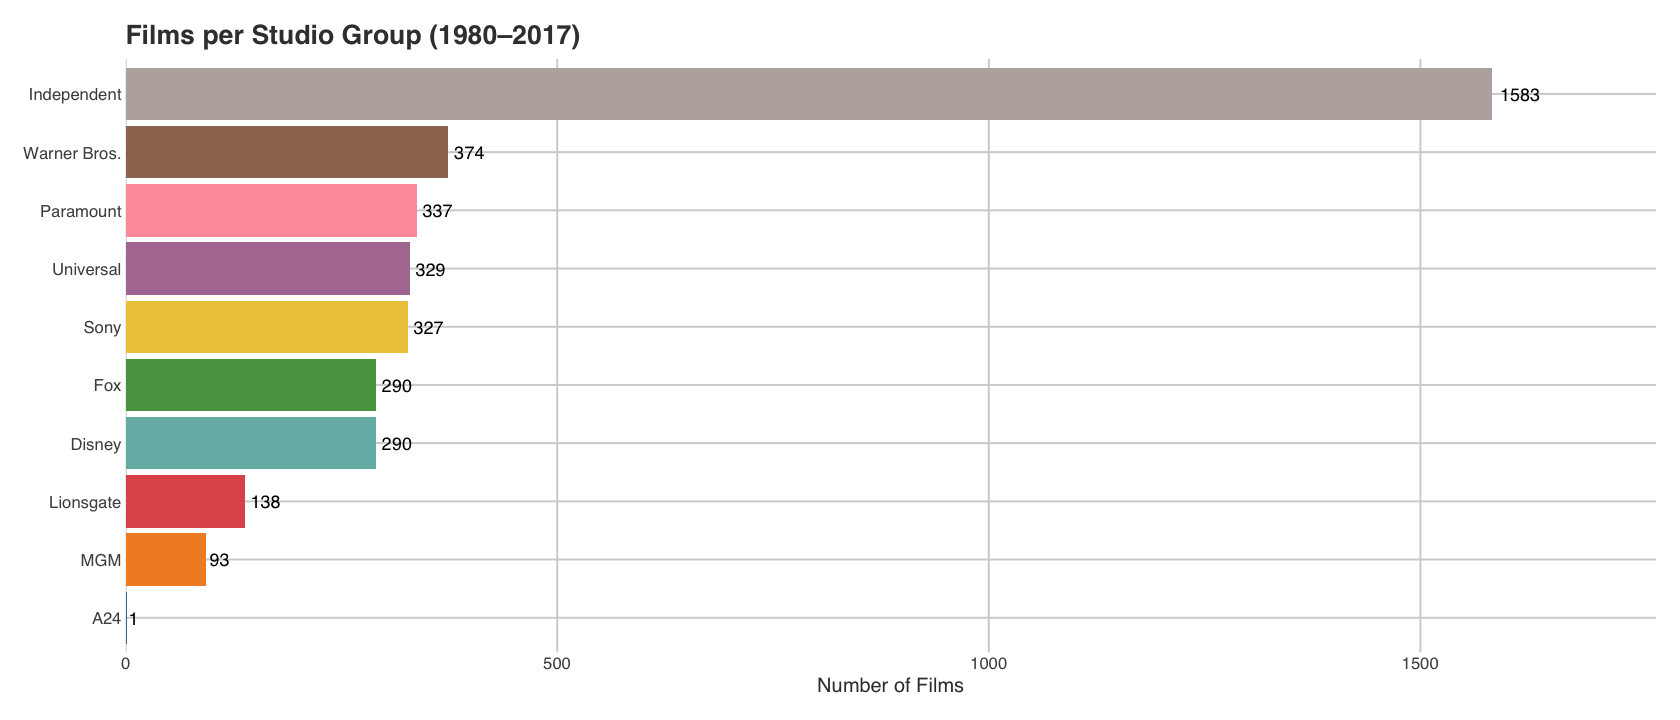

In [3]:
# Films per studio group
df %>%
  count(studio_group, name = 'films') %>%
  arrange(films) %>%
  mutate(studio_group = fct_inorder(studio_group)) %>%
  ggplot(aes(x = films, y = studio_group, fill = studio_group)) +
  geom_col(show.legend = FALSE) +
  geom_text(aes(label = films), hjust = -0.2, size = 3.8) +
  scale_x_continuous(expand = expansion(mult = c(0, 0.12))) +
  scale_fill_tableau() +
  labs(
    title = 'Films per Studio Group (1980–2017)',
    x = 'Number of Films',
    y = NULL
  )

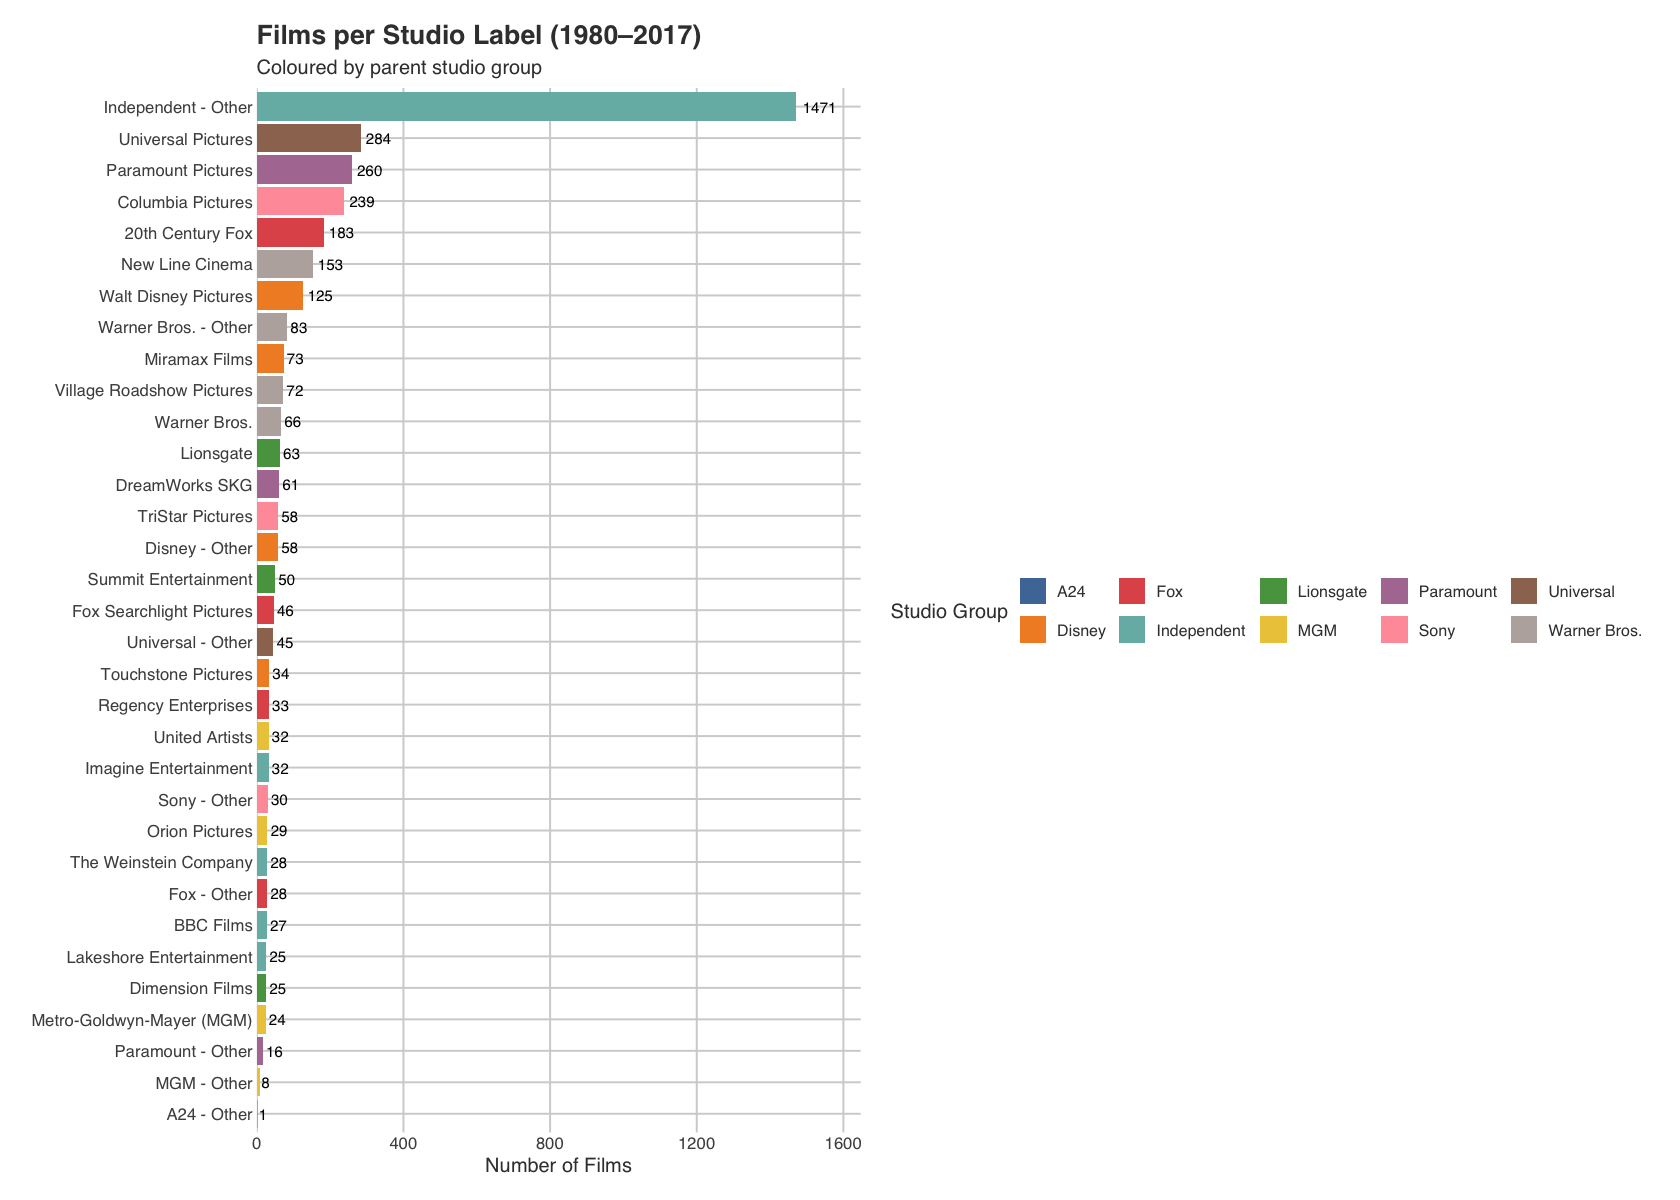

In [4]:
# Films per studio label (sub-studio breakdown)
options(repr.plot.width = 14, repr.plot.height = 10)

df %>%
  count(studio_label, studio_group, name = 'films') %>%
  arrange(films) %>%
  mutate(studio_label = fct_inorder(studio_label)) %>%
  ggplot(aes(x = films, y = studio_label, fill = studio_group)) +
  geom_col() +
  geom_text(aes(label = films), hjust = -0.2, size = 3.2) +
  scale_x_continuous(expand = expansion(mult = c(0, 0.12))) +
  scale_fill_tableau(name = 'Studio Group') +
  labs(
    title = 'Films per Studio Label (1980–2017)',
    subtitle = 'Coloured by parent studio group',
    x = 'Number of Films',
    y = NULL
  ) +
  theme(legend.position = 'right')

## 3. Release Year Distribution

decade,film_count
<dbl>,<int>
1980,396
1990,699
2000,1377
2010,1290


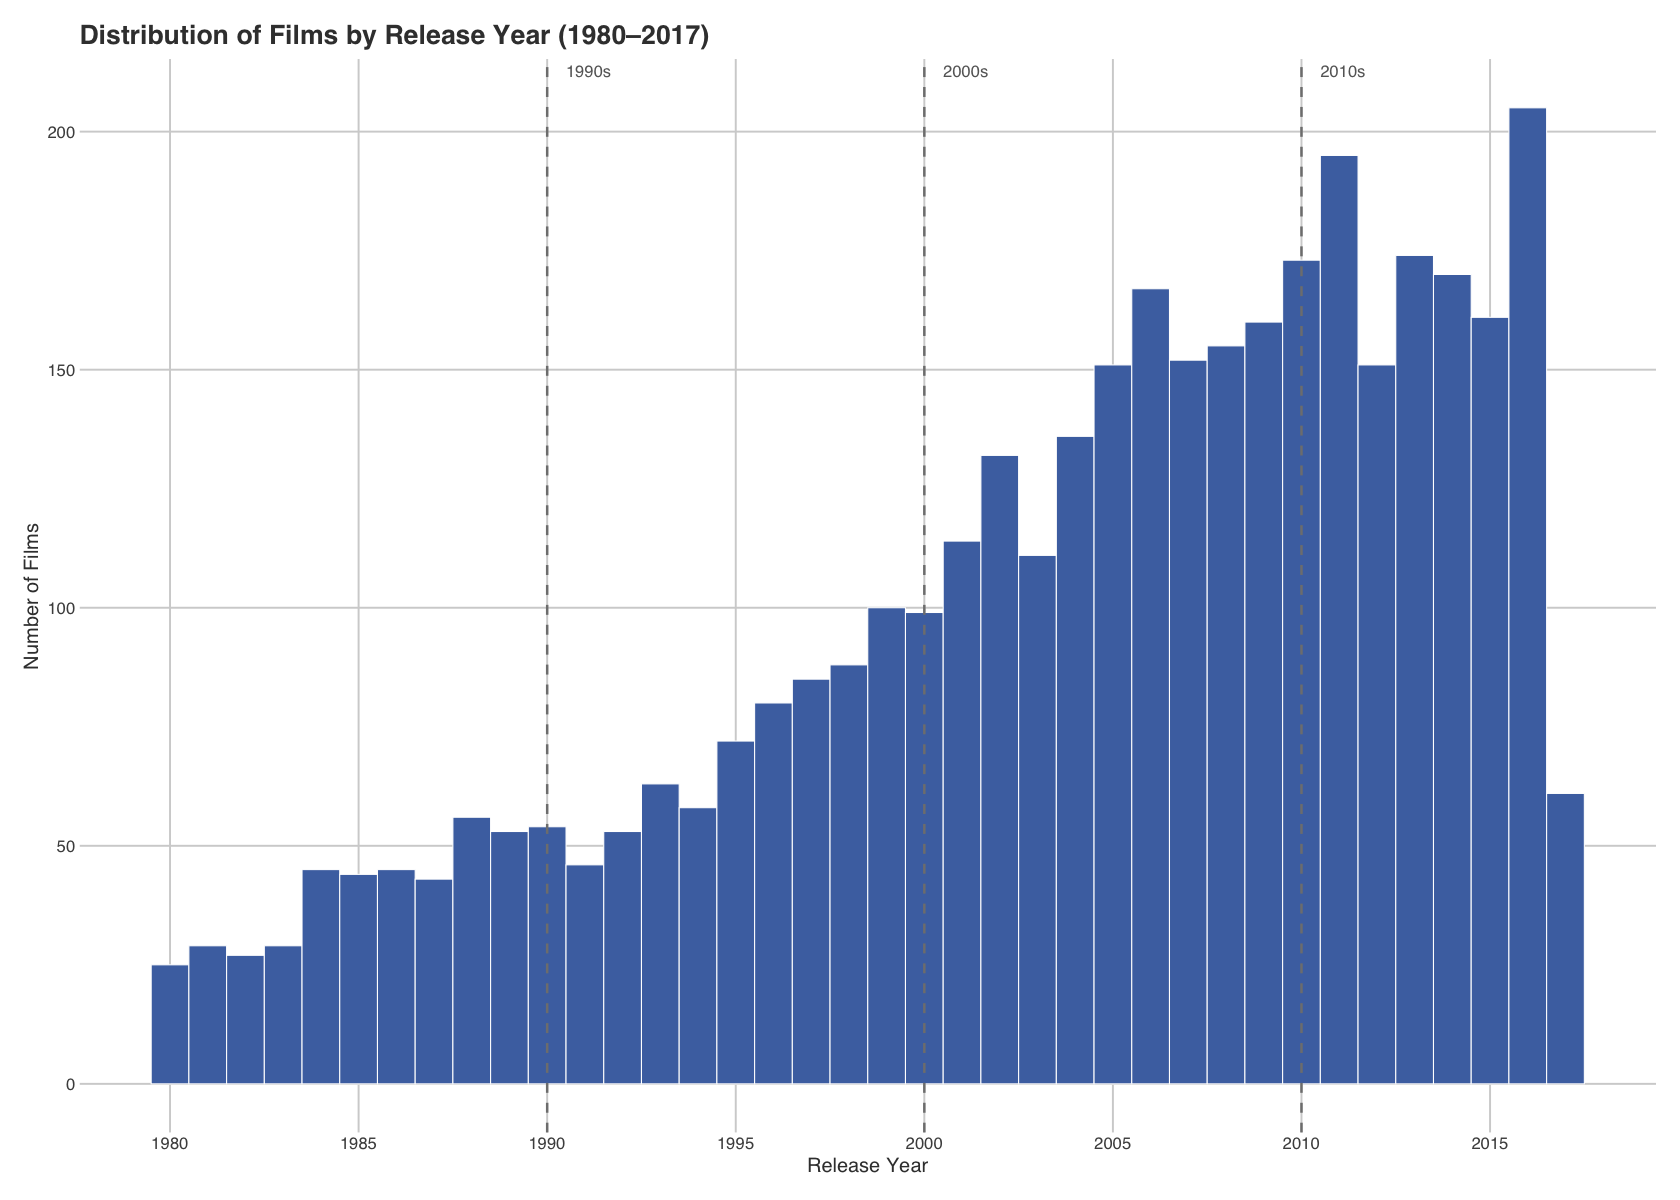

In [5]:
df %>%
  ggplot(aes(x = year)) +
  geom_histogram(binwidth = 1, fill = '#4C72B0', color = 'white', linewidth = 0.3) +
  geom_vline(xintercept = c(1990, 2000, 2010), linetype = 'dashed',
             color = 'grey50', linewidth = 0.7) +
  annotate('text', x = c(1990.5, 2000.5, 2010.5),
           y = Inf, vjust = 1.5, hjust = 0,
           label = c('1990s', '2000s', '2010s'),
           color = 'grey40', size = 3.5) +
  scale_x_continuous(breaks = seq(1980, 2017, by = 5)) +
  labs(
    title = 'Distribution of Films by Release Year (1980–2017)',
    x = 'Release Year',
    y = 'Number of Films'
  )

df %>% count(decade, name = 'film_count') %>% arrange(decade)